# 140 · Freq tokens and laser tokens: what the model needs vs how loud they are

Run `decres-rescale-aug10-v1` (src9 transformer4, res decoder, rescaled latent, augs on 10% of samples, ep300). Eval is **eager fp32** (compile eval bug).

- **Freq token** = one of 18 bands (65 FFT bins ≈ 50 Hz, 100–1000 Hz). **Laser token** = one of 100 lasers on a 10×10 grid on the laser wall.
- **Importance** = ΔIoU = IoU(clean) − IoU(that one token removed with the model's own token masks; nb136 masking).
- **Loudness** = the model input |FFT| / σ_sample, averaged over everything except the token.
- **Relative** (`RELATIVE`, `REL_IMP`, `REL_LOUD`): importance = 100·ΔIoU_k / Σ|ΔIoU|, loudness = 100·v_k / Σv (magnitude, not squared).
- **Samples.** 2b and 2c: nb136 `subset720` = 60 single-object samples × 4 ID objects × 3 boxes per set (`scripts/nb140_cache.py` → `runs/_src9_cache/nb140/{train,test}.npz`). 2c-A spectrum and 2d: **every** single-object ID sample (train 2242 / 3802 / 3163, test 584 / 830 / 777 for gastro / cardboard / plastic) plus the unseen-speaker sets (`scripts/nb140_extra.py` → `extra.npz`; preds from the nb136 base pass, IoU matches the nb140 cache to 2e-4).
- **Split.** train = training samples, test = eval splits (unseen positions). Single-token masking on test is noise-dominated (in ~60% of test samples some band's removal *raises* IoU by > .05, vs 12–20% on train), so mechanism claims use **train**; test is quoted alongside.

Layout: each figure is followed by the claims it decides (verdict + the panel and numbers). **Every figure is drawn for `SPLIT`** (default train); test numbers are quoted in the text where they differ. §1 figure 2b (bands + lasers), §2 figure 2c (spectrum + multi-band removal), §3 figure 2d (speaker, position, distance, vibration axis).

In [9]:
import sys, subprocess, numpy as np, matplotlib.pyplot as plt, matplotlib as mpl
from pathlib import Path
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, Normalize
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE, OUT = ROOT / "runs/_src9_cache/nb140", ROOT / "notebooks/out"

SPLIT = "train"         # "train" | "test": default split for the claims (train: single-token masking is noise-dominated on test, see the claims)
RELATIVE = True         # master switch: per-token shares (%) instead of absolute units
REL_IMP = RELATIVE      # importance: 100 · ΔIoU_k / Σ_k |ΔIoU_k|   (signed share of all changes)
REL_LOUD = RELATIVE     # loudness:   100 · v_k / Σ_k v_k           (share of total |FFT| magnitude, not squared)

if not (CACHE / "test.npz").exists(): subprocess.run([sys.executable, "scripts/nb140_cache.py"], check=True, cwd=ROOT)   # ~10 min, one GPU
if not (CACHE / "extra.npz").exists(): subprocess.run([sys.executable, "scripts/nb140_extra.py"], check=True, cwd=ROOT)   # ~5 min, CPU
E = dict(np.load(CACHE / "extra.npz"))   # every single-object ID sample: iou, com_t/com_p (row, col), spk, pos, split, hw (crop px), axis_e, spec (1170, 2)
D = {s: dict(np.load(CACHE / f"{s}.npz")) for s in ("train", "test")}
BX, OBJ = ["gastro", "cardboard", "plastic"], ["candle", "red-cube", "soap dispenser", "vase"]
OBJN = {"candle": "candle", "red-cube": "cube", "soap dispenser": "soap", "vase": "vase"}
HZ = 100 + (np.arange(18) * 65 + 32) * 900 / 1169                            # band centres (Hz), 18 bands × 65 bins ≈ 50 Hz
EDGE = 100 + np.arange(19) * 65 * 900 / 1169
for s, d in D.items():
    d["vb_b"], d["vb_l"] = d["vb"].mean(1), d["vb"].mean(2)                    # freq-token loudness (mean over lasers, axes, bins) | laser-token loudness (mean over bands, axes)
    print(f"{s:5s} clean IoU", {b: round(float(d["clean"][d["box"] == b].mean()), 3) for b in BX}, "n", {b: int((d["box"] == b).sum()) for b in BX})

def rel(v, on):  # rows of token values -> % share; importance signed over Σ|·|, loudness over Σ (all positive)
    v = np.atleast_2d(v); return 100 * v / np.abs(v).sum(-1, keepdims=True) if on else v
def prof(s, b, kind, o=None):  # box (and object) mean token profile, before the relative step
    d = D[s]; m = (d["box"] == b) & ((d["obj"] == o) if o else True); return d[kind][m].mean(0)

rho = lambda a, b: stats.spearmanr(a, b)[0]
INK, MUTE, GRID = "#0b0b0b", "#52514e", "#e4e3df"
DIV = LinearSegmentedColormap.from_list("div", ["#a32b2a", "#e34948", "#f3b3ad", "#f0efec", "#9ec5f4", "#2a78d6", "#0d366b"])   # red = removing helps, blue = token needed
SEQ = LinearSegmentedColormap.from_list("seq", ["#fbf3ee", "#f6c6ac", "#eb6834", "#a8401a", "#5a1f08"])                       # loudness, one hue light->dark
BOXC = {"gastro": "#2a78d6", "cardboard": "#eb6834", "plastic": "#1baf7a"}                                                     # categorical slots 1-3 (validated all-pairs)
plt.rcParams.update({"figure.dpi": 100, "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
                     "axes.labelcolor": MUTE, "xtick.color": MUTE, "ytick.color": MUTE, "axes.edgecolor": "#b8b7b2", "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "savefig.bbox": "tight", "pdf.fonttype": 42})
def save(fig, name): fig.savefig(OUT / f"140_{name}.pdf"); plt.show()

train clean IoU {'gastro': 0.911, 'cardboard': 0.909, 'plastic': 0.926} n {'gastro': 240, 'cardboard': 240, 'plastic': 240}
test  clean IoU {'gastro': 0.711, 'cardboard': 0.619, 'plastic': 0.692} n {'gastro': 240, 'cardboard': 240, 'plastic': 240}


## 1 · Figure 2b: loudness vs importance per token, all objects averaged

One row per box. Left: the 18 freq tokens as two strips sharing the frequency axis, loudness on top and importance below; dashed line = 300 Hz; outlined = top 3. Right: the 10×10 laser grid, loudness next to importance; outlined = top 10. Each row's subtitle carries Pearson r and Spearman ρ between the loudness and importance strips, the share of |FFT| and of importance below 300 Hz, the number of bands holding 90% of |importance|, and clean IoU. Drawn for `SPLIT`.

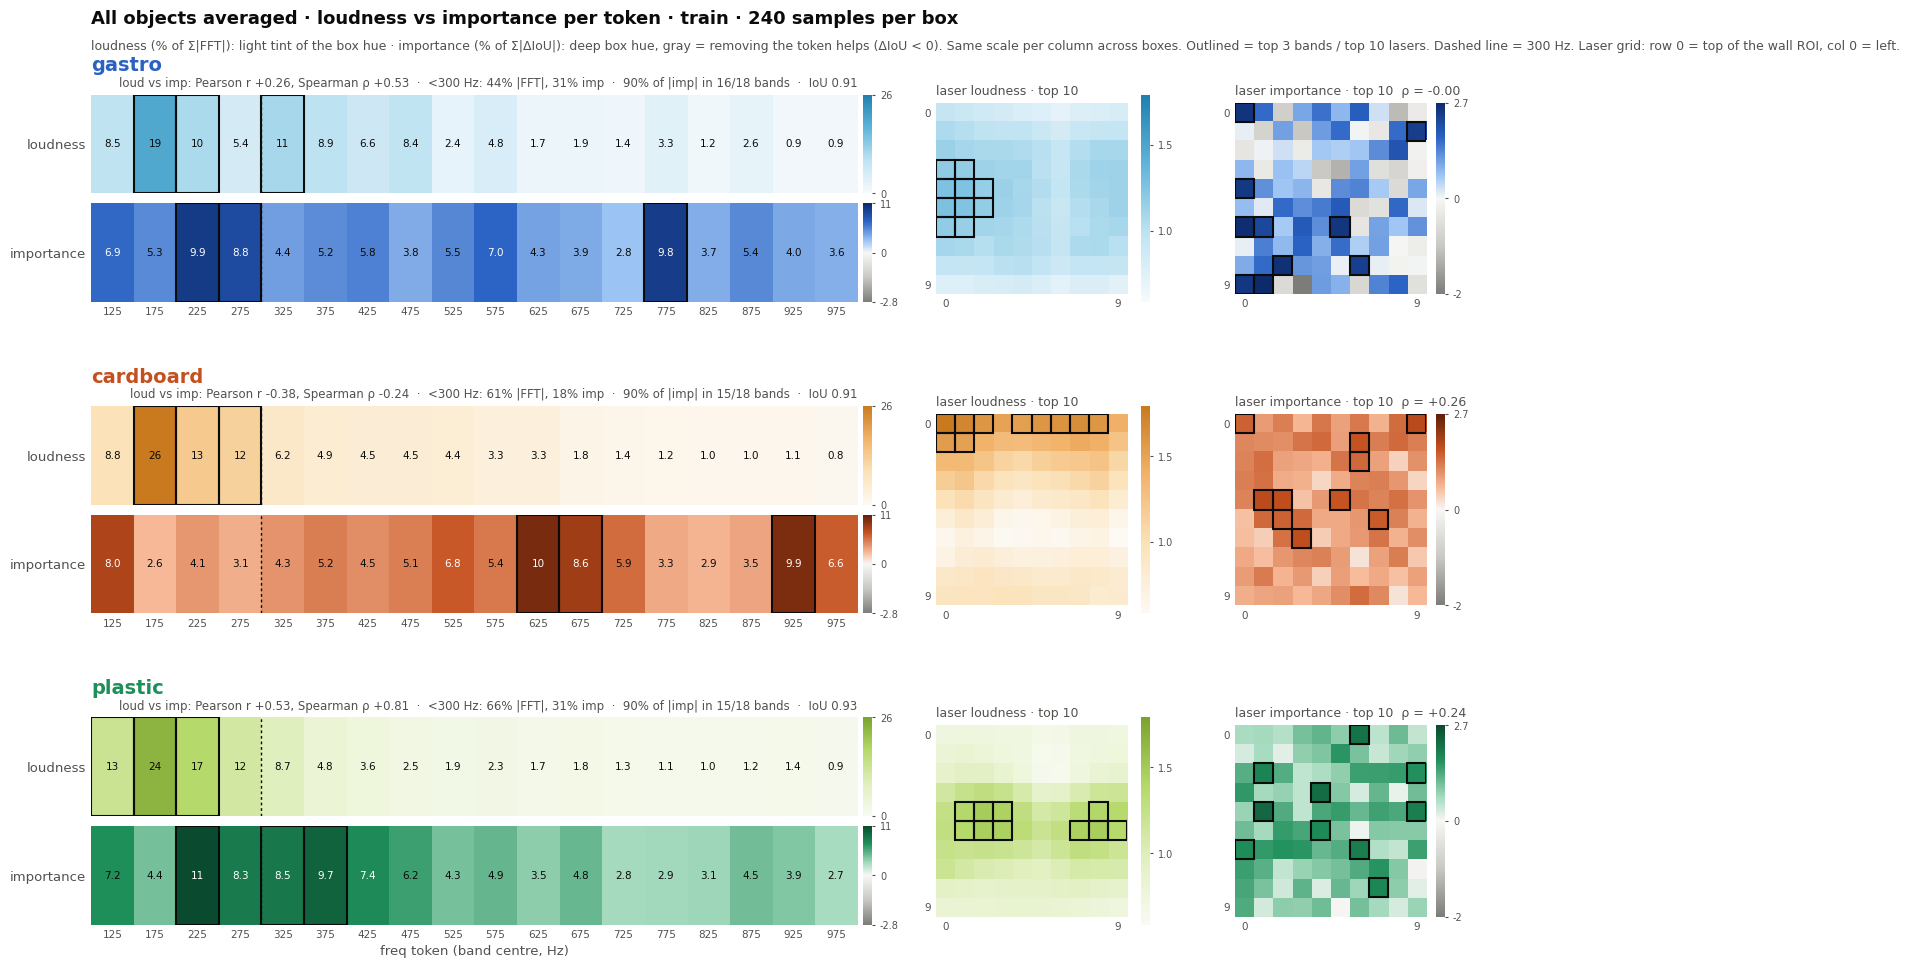

In [2]:
FAM = {"gastro": (["#f7fafd", "#bfe3f2", "#5fb4d9", "#1f7fae"], ["#f7f7f5", "#9ec5f4", "#2a62c4", "#0d2a6b"]),        # (loudness: white -> sky, importance: white -> navy)
       "cardboard": (["#fdf9f3", "#fbe2b8", "#f2b36b", "#c97a1e"], ["#f7f7f5", "#f6b896", "#c4501f", "#5e1f08"]),  # amber | red-brown
       "plastic": (["#f8fbf2", "#e0efbd", "#b5d96a", "#7aa22c"], ["#f7f7f5", "#a8dcc0", "#1f8f5a", "#0a4a2e"])}    # yellow-green | deep green
NEG = ["#7d7c78", "#c9c8c3"]                                                                                         # importance < 0 -> gray ramp
CMAPS = {b: (LinearSegmentedColormap.from_list(f"l{b}", l), LinearSegmentedColormap.from_list(f"i{b}", [(0, NEG[0]), (.25, NEG[1]), (.5, i[0]), (.62, i[1]), (.82, i[2]), (1, i[3])])) for b, (l, i) in FAM.items()}
def outline(a, idx, ncol=None):
    for t in idx:
        r, c = (0, t) if ncol is None else (t // ncol, t % ncol)
        a.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, ec=INK, lw=1.5, zorder=5))
def lum(rgba): r, g, b = rgba[:3]; return .2126 * r + .7152 * g + .0722 * b
def avg_fig(s):
    fig = plt.figure(figsize=(15, 10))
    gs = fig.add_gridspec(3, 2, width_ratios=[2.55, 1.6], hspace=.5, wspace=.1, left=.08, right=.97, top=.89, bottom=.06)
    V = {(b, k): rel(prof(s, b, key), on)[0] for b in BX for k, key, on in (("Fl", "vb_b", REL_LOUD), ("Fi", "mask_b", REL_IMP), ("Ll", "vb_l", REL_LOUD), ("Li", "mask_l", REL_IMP))}
    mx = {k: max(V[b, k].max() for b in BX) for k in V for k in ("Fl", "Fi", "Ll", "Li")}
    mn = {k: min(V[b, k].min() for b in BX) for k in ("Fi", "Li")}
    nrm = {"Fl": Normalize(0, mx["Fl"]), "Ll": Normalize(min(V[b, "Ll"].min() for b in BX), mx["Ll"]),
           "Fi": TwoSlopeNorm(0, min(mn["Fi"], -.25 * mx["Fi"]), mx["Fi"]), "Li": TwoSlopeNorm(0, min(mn["Li"], -.25 * mx["Li"]), mx["Li"])}   # gray side ≥ 1/4 of the blue side
    ui, ul = ("% of Σ|ΔIoU|" if REL_IMP else "ΔIoU"), ("% of Σ|FFT|" if REL_LOUD else "|FFT| / σ")
    for r, b in enumerate(BX):
        cl, ci = CMAPS[b]
        L = gs[r, 0].subgridspec(2, 2, hspace=.1, wspace=.015, width_ratios=[1, .012]); R = gs[r, 1].subgridspec(1, 4, wspace=.12, width_ratios=[1, .05, .3, 1])
        for i, k in enumerate(("Fl", "Fi")):
            a = fig.add_subplot(L[i, 0]); v = V[b, k]; cm = cl if k == "Fl" else ci
            h = a.imshow(v[None], cmap=cm, norm=nrm[k], aspect="auto", interpolation="nearest")
            for j in range(18): a.text(j, 0, f"{v[j]:.0f}" if abs(v[j]) >= 10 else f"{v[j]:.1f}", ha="center", va="center", fontsize=7.5,
                                       color="white" if lum(cm(nrm[k](v[j]))) < .45 else INK)
            outline(a, np.argsort(-v)[:3])
            a.set_yticks([0], ["loudness" if k == "Fl" else "importance"]); a.tick_params(length=0); [sp.set_visible(False) for sp in a.spines.values()]
            a.set_xticks(range(18), [f"{hz:.0f}" for hz in HZ] if i else [], fontsize=7.5)
            a.axvline(3.5, color=INK, lw=1, ls=(0, (2, 2)), zorder=6)                                  # 300 Hz = edge between the 275 and 325 Hz bands
            if i == 0:
                fl, fi = V[b, "Fl"] / V[b, "Fl"].sum(), V[b, "Fi"] / np.abs(V[b, "Fi"]).sum(); lo = HZ < 300
                n90 = int(np.searchsorted(np.cumsum(np.sort(np.abs(fi))[::-1]), .9) + 1)
                a.set_title(b, loc="left", color=FAM[b][1][2], fontsize=14, pad=17)
                a.text(1, 1.05, f"loud vs imp: Pearson r {stats.pearsonr(V[b, 'Fl'], V[b, 'Fi'])[0]:+.2f}, Spearman ρ {rho(V[b, 'Fl'], V[b, 'Fi']):+.2f}  ·  "
                       f"<300 Hz: {100 * fl[lo].sum():.0f}% |FFT|, {100 * fi[lo].sum():.0f}% imp  ·  90% of |imp| in {n90}/18 bands  ·  IoU {D[s]['clean'][D[s]['box'] == b].mean():.2f}",
                       transform=a.transAxes, ha="right", va="bottom", fontsize=8.5, color=MUTE)
            if i == 1 and r == 2: a.set_xlabel("freq token (band centre, Hz)")
            cb = fig.colorbar(h, cax=fig.add_subplot(L[i, 1])); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=7, length=2)
            cb.set_ticks([nrm[k].vmin, 0, nrm[k].vmax] if k == "Fi" else [0, nrm[k].vmax], labels=([f"{nrm[k].vmin:.2g}", "0"] if k == "Fi" else ["0"]) + [f"{nrm[k].vmax:.2g}"])
        for i, k in enumerate(("Ll", "Li")):
            a = fig.add_subplot(R[3 * i]); m = V[b, k]; cm = cl if k == "Ll" else ci
            h = a.imshow(m.reshape(10, 10), cmap=cm, norm=nrm[k], interpolation="nearest"); outline(a, np.argsort(-m)[:10], 10)
            a.set_xticks([0, 9]); a.set_yticks([0, 9]); a.tick_params(length=0, labelsize=7.5); [sp.set_visible(False) for sp in a.spines.values()]
            a.set_title(("laser loudness · top 10" if k == "Ll" else f"laser importance · top 10  ρ = {rho(V[b, 'Ll'], V[b, 'Li']):+.2f}"), loc="left", fontsize=9, fontweight="normal", color=MUTE)
            cb = fig.colorbar(h, cax=fig.add_subplot(R[1]) if i == 0 else a.inset_axes([1.05, 0, .05, 1])); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=7, length=2)
            if k == "Li": cb.set_ticks([nrm[k].vmin, 0, nrm[k].vmax], labels=[f"{nrm[k].vmin:.2g}", "0", f"{nrm[k].vmax:.2g}"])
            else: cb.ax.locator_params(nbins=4)
    fig.suptitle(f"All objects averaged · loudness vs importance per token · {s} · 240 samples per box", x=.08, y=.975, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.text(.08, .935, f"loudness ({ul}): light tint of the box hue · importance ({ui}): deep box hue, gray = removing the token helps (ΔIoU < 0). "
             "Same scale per column across boxes. Outlined = top 3 bands / top 10 lasers. Dashed line = 300 Hz. Laser grid: row 0 = top of the wall ROI, col 0 = left.", fontsize=9, color=MUTE)
    save(fig, f"avg_{s}{'_relimp' if REL_IMP else ''}{'_relloud' if REL_LOUD else ''}")
avg_fig(SPLIT)

### Claims decided by figure 2b
Verdicts: ✅ supported · 🟡 partly · ❌ refuted. Numbers are gastro / cardboard / plastic. Claims are numbered in the order they were posed.

### Claim 3 · "The signal looks alike in every box" → 🟡 partly
- **Band envelope: ✅.** 2b loudness strips. Box-to-box Pearson r of the 18-band loudness profile = .87 (gastro–cardboard), .86 (gastro–plastic), .96 (cardboard–plastic), train. All three boxes peak in the 175 Hz band and carry ≤ 3.3% per band above 600 Hz.
- **Fine structure: ❌.** 2c-A. The resonance peaks differ: gastro 125, 185, 322, 385, 399, 566, 771, 864 Hz; cardboard 115, 141, 159, 175, 259, 505, 604, 954 Hz; plastic 115, 157, 195, 211, 304, 567, 656, 924 Hz. Only the ~115–125 and ~566 Hz peaks recur.
- **Laser map: ❌.** 2b laser loudness. Gastro is loudest on the left columns, cardboard on the top row, plastic in a middle horizontal band.

### Claim 4 · "The 175 Hz band is the loudest everywhere, and 44 / 61 / 66% of the |FFT| is below 300 Hz" → ✅ supported (at band resolution)
- 2b loudness strips (outlined). 175 Hz is the loudest band in all boxes: 19.5 / 26.5 / 23.5% of |FFT| (train), 19.8 / 26.5 / 23.7% (test).
- 2b subtitles. Below 300 Hz: 44 / 61 / 66% on both splits (train 43.9 / 60.7 / 65.9).
- At full resolution (2c-A) the single loudest bin is 185 / 175 / 157 Hz, so "175 Hz" is a band statement. Plastic's loudest bin falls in the 175 Hz band (150–200 Hz).

### Claim 6 · "Pearson correlation between loudness and importance (per box)" → reported
2b subtitles (box-mean 18-band profiles):

| | gastro | cardboard | plastic |
|---|---|---|---|
| Pearson r, train | +.26 | −.38 | +.53 |
| Spearman ρ, train | +.53 | −.24 | +.81 |
| Pearson r, test | +.17 | −.26 | +.67 |
| Spearman ρ, test | +.31 | −.37 | +.59 |
| mean per-sample Pearson r, train / test | +.05 / +.01 | −.12 / −.07 | +.12 / +.08 |

- The gap between Spearman and Pearson in gastro (train .53 vs .26) means the rank order loosely follows loudness. The one very loud band (175 Hz, 19.5%) is not very important (5.3%), and that outlier pulls Pearson down.
- Lasers: 2b laser titles give ρ −.00 / +.26 / +.24 (train), +.09 / +.27 / +.13 (test).

### Claim 9 · "Each box relies on different freqs" → ✅ supported
2b importance strips vs loudness strips. Box-to-box Pearson r of the importance profile, compared with the loudness profile (claim 3):

| pair | importance r, train | importance r, test | loudness r |
|---|---|---|---|
| gastro–cardboard | −.39 | −.25 | .87 |
| gastro–plastic | +.46 | +.32 | .86 |
| cardboard–plastic | −.23 | −.13 | .96 |

- The inputs share an envelope, but the readouts don't. Cardboard is high-frequency (claim 10), plastic low-frequency (claim 11), and gastro mixed (claim 12).
- Gastro and plastic share the 225–275 Hz bands, which is why their r is positive.

### Claim 10 · "Cardboard relies on 625–975 Hz (48% of total importance)" → ✅ supported
2b, cardboard importance strip.
- **Where the 48% comes from.** It is the 4 test top bands 925 / 675 / 975 / 625 Hz = 17.1 + 12.3 + 9.5 + 9.2 = **48.1%**. The whole 625–975 Hz range (8 bands) holds 67.2% on test and 50.9% on train.
- **Train.** The top 3 are 625 (10.1%), 925 (9.9%) and 675 Hz (8.6%).
- **Little energy.** These bands carry only 0.8–3.3% of |FFT| each, 11.6% in total (2b loudness, train).

### Claim 11 · "Plastic relies on 224 Hz (15.5%)" → ✅ supported, but it's the top of a low-band block
2b, plastic importance strip.
- **The 225 Hz band is the top band on both splits:** 15.5% of importance on test, 11.2% on train.
- **The block.** The low bands 125–425 Hz hold 68% (test) and 57% (train) of importance, so 225 Hz is the peak of a block rather than a lone band.
- **Not significant alone.** Its lead over the runner-up is not significant (claim 13): train 225 vs 375 Hz differ by +.005 IoU, CI [−.003, +.013].

### Claim 12 · "Gastro ?" → gastro relies on no band in particular: the flattest profile, spread over low *and* high bands
2b, gastro importance strip.
- **Top bands.** Train: 225 (9.9%), 775 (9.8%), 275 (8.8%), 575 Hz (7.0%). Test: 125 (8.6%), 575 (8.1%), 375 (8.1%), 275 Hz (7.5%).
- **Narrow range.** Every band holds 2.8–9.9% (train). It takes **16 / 18** bands to reach 90% of importance, the most of any box.
- **The top band is unstable.** 225 Hz is top in only 54% of bootstrap resamples on train. On test, 13 different bands come out top across resamples.
- **Low and high bands share it.** Below 300 Hz holds 31% (train) and 625–975 Hz holds 37%. Gastro sits between cardboard (high) and plastic (low).

### Claim 13 · "There is no one freq band that is most important" → ✅ supported (one borderline exception: cardboard 925 Hz on test)
2b importance strips, tested with a bootstrap over samples of the top band's ΔIoU minus the 2nd band's.
- **Train: the top band never stands out.** gastro 225 vs 775 Hz: +.0007, 95% CI [−.008, +.010]. cardboard 625 vs 925 Hz: +.0012, CI [−.009, +.011]. plastic 225 vs 375 Hz: +.005, CI [−.003, +.013].
- **The top band changes under resampling.** It stays top in only 54 / 59 / 88% of resamples.
- **Test exception.** Cardboard 925 Hz leads 675 Hz by +.012, CI [−.0004, +.024], and is top in 96% of resamples. That is borderline, and only on the noisy split.
- **Size.** The largest single-band share is 9.9 / 10.1 / 11.2% (train), against a uniform 5.6%.

### Claim 14 · "Importance is spread out: reaching 90% of total importance takes 12–15 of the 18 bands" → ✅ supported (15–16 on train)
2b subtitles ("90% of |imp| in N/18 bands"): train **16 / 15 / 15**, test **15 / 14 / 12**. The quoted 12–15 was the test range; on train it is even more spread. 2c-B agrees: no small set of bands is critical. Removing the single most important band (train order) keeps 96 / 94 / 96% of IoU and the top 3 keep 87 / 82 / 89% (train). IoU only halves after removing 9 / 8 / 8 bands in importance order, 8 / 8 / 7 loudest-first, or 11 / 10 / 14 random bands.

## 2 · Figure 2c: the spectrum and multi-band removal

Rows = boxes. **A** mean model input |FFT|/σ at full resolution (1170 bins, **linear**), ▼ = the 8 most prominent resonance peaks; the shading extends below 0 so the bars = band importance (% of Σ|ΔIoU|) sit underneath the spectrum; black outline = 3 most important bands; dark fill + thick line = 3 loudest bands. **B** IoU / clean IoU after removing the K loudest / K quietest / K random bands at once (dotted line and labels = K 5).

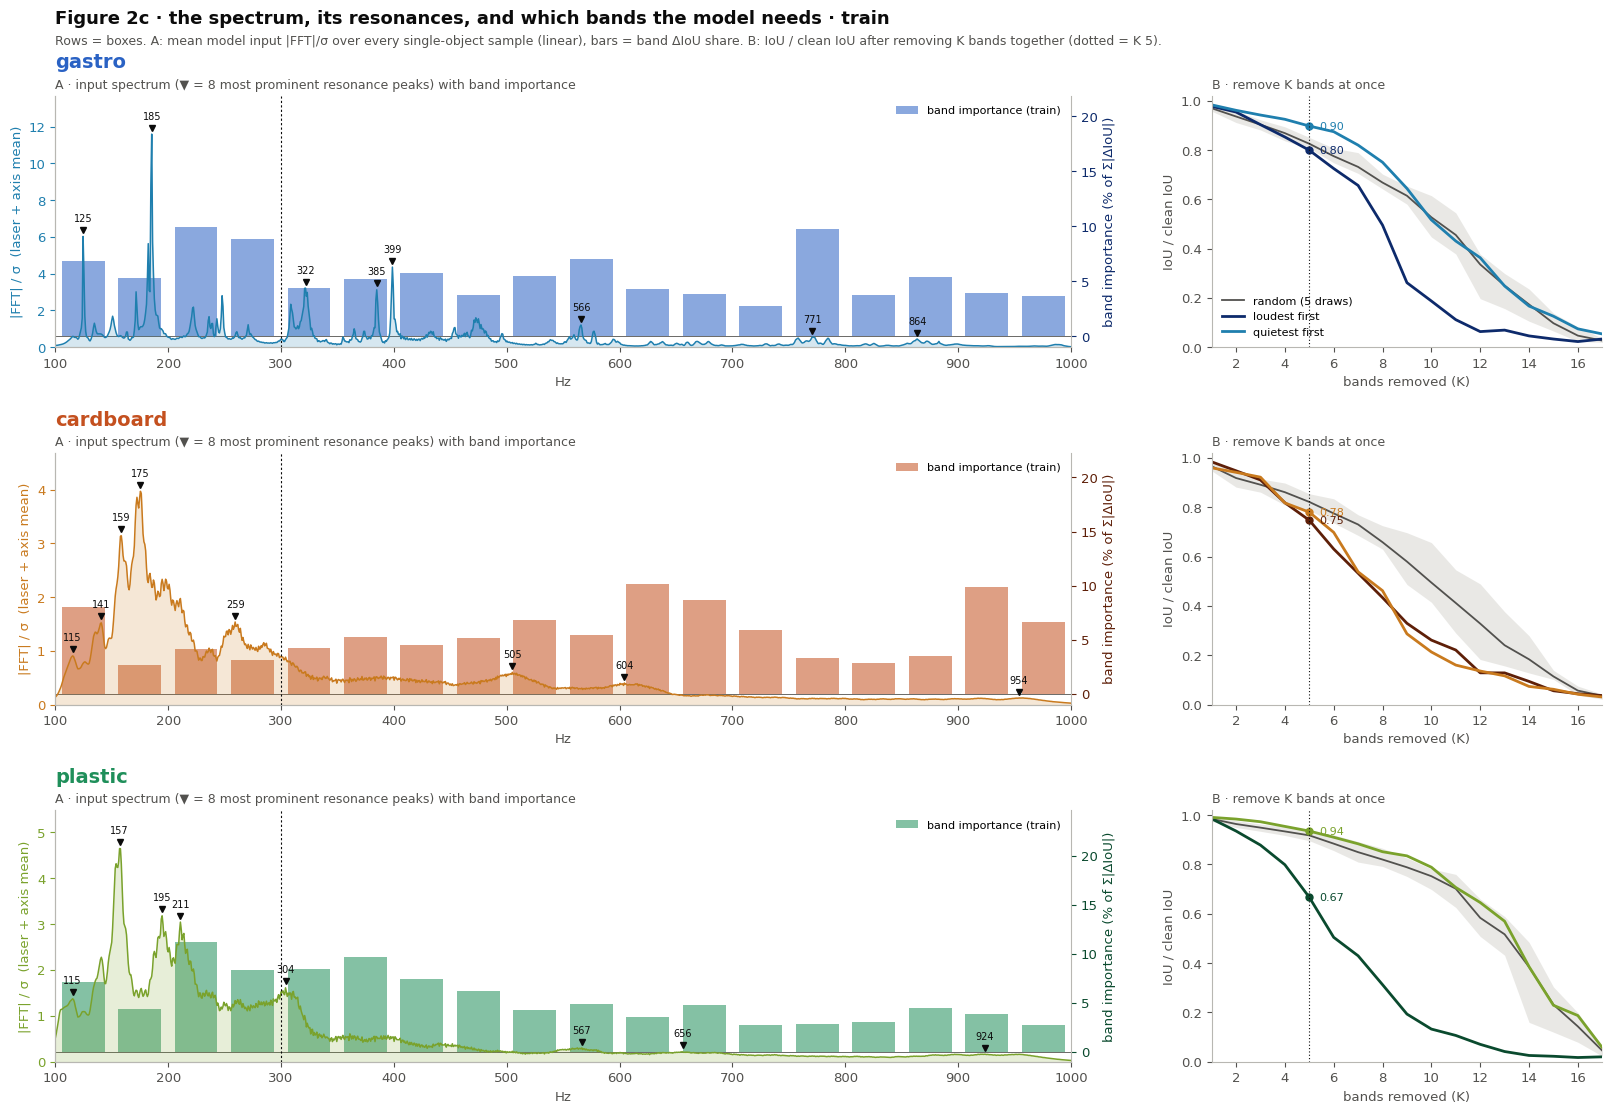

In [7]:
from scipy.signal import find_peaks
FQ = 100 + np.arange(1170) * 900 / 1169                                             # the 1170 bins (Hz), same grid as HZ
SPK = {1: (1, 0), 3: (.8, 1), 4: (.6, 1), 5: (.4, 1), 7: (0, .7)}                   # record.ipynb SPEAKER_POSITION (x, y) in the overhead crop, y = 0 at the bottom
LASER = (.37, .65)                                                                  # laser patch: centred span of the bottom (laser) wall, nb96
sp = np.array([(1 - SPK[k][1], SPK[k][0]) for k in E["spk"]])                       # speaker as floor (row, col)
E["d_spk"], E["d_las"] = np.linalg.norm(E["com_t"] - sp, axis=1), 1 - E["com_t"][:, 0]   # distances in box fractions; laser wall = bottom row (row = 1)
E["kind"] = np.where(np.char.endswith(E["split"], "-unseen"), "spk4", np.where(np.char.endswith(E["split"], "-baseline"), "spk4-base", "id"))
# paired residual = IoU − mean IoU of the speakers recorded at the same position (removes position; only distance-to-speaker varies within a position)
grp = np.char.add(np.char.add(E["split"], "|"), E["pos"].astype(str))
_, inv = np.unique(grp, return_inverse=True); cnt = np.bincount(inv); mu = np.bincount(inv, E["iou"]) / cnt
E["res"] = np.where(cnt[inv] > 1, E["iou"] - mu[inv], np.nan)
sel = lambda st, b, kind="id": (E["set"] == st) & (E["box"] == b) & (E["kind"] == kind)
ci = lambda v: 1.96 * np.std(v) / np.sqrt(max(len(v), 1))

def geo(st, b):  # every number the claims quote from the companion figure
    m = sel(st, b); r = E["res"][m]; ok = ~np.isnan(r); e = np.abs(E["com_p"][m] - E["com_t"][m]) * E["hw"][m]   # (row, col) CoM error in crop px
    return dict(n=int(m.sum()), spk={k: E["iou"][m & (E["spk"] == k)].mean() for k in (1, 3, 5, 7) if (m & (E["spk"] == k)).any()},
                s4=E["iou"][sel(st, b, "spk4")].mean() if sel(st, b, "spk4").any() else np.nan, s4b=E["iou"][sel(st, b, "spk4-base")].mean() if sel(st, b, "spk4-base").any() else np.nan,
                r_spk=rho(E["iou"][m], E["d_spk"][m]), r_spk_res=rho(r[ok], E["d_spk"][m][ok]), r_las=rho(E["iou"][m], E["d_las"][m]),
                xs=100 * (E["axis_e"][m, 0] / E["axis_e"][m].sum(1)).mean(), err=e.mean(0), errf=np.abs(E["com_p"][m] - E["com_t"][m]).mean(0),
                r_xy=rho(E["axis_e"][m, 0] / E["axis_e"][m].sum(1), e[:, 0] - e[:, 1]))
G = {(st, b): geo(st, b) for st in ("train", "test") for b in BX}

def drop(s, b, nm): return D[s][f"c|{b}|band|{nm}"] / D[s]["clean"][D[s]["box"] == b].mean()
def floor_grid(s, b, nb_=7):  # mean IoU per 7×7 floor bin of the true CoM (NaN where < 3 samples)
    m = sel(s, b); ij = np.clip((E["com_t"][m] * nb_).astype(int), 0, nb_ - 1); S_, N_ = np.zeros((nb_, nb_)), np.zeros((nb_, nb_))
    np.add.at(S_, (ij[:, 0], ij[:, 1]), E["iou"][m]); np.add.at(N_, (ij[:, 0], ij[:, 1]), 1); return np.where(N_ >= 3, S_ / np.maximum(N_, 1), np.nan)

def fig_signal(s=SPLIT):
    fig = plt.figure(figsize=(17, 11.5))
    gs = fig.add_gridspec(3, 2, hspace=.42, wspace=.2, width_ratios=[2.6, 1], left=.06, right=.97, top=.9, bottom=.06)
    for r, b in enumerate(BX):
        cl, ci_, dk = FAM[b][0][3], FAM[b][1][2], FAM[b][1][3]
        # A · fine spectrum (linear) + band importance
        a = fig.add_subplot(gs[r, 0]); spec = E["spec"][sel(s, b)].astype(np.float32).mean((0, 2)); sm = spec.max(); fl = -.6 * sm    # spectrum floor sits below 0 -> room for the bars
        a.fill_between(FQ, fl, spec, color=cl, alpha=.16, lw=0); a.plot(FQ, spec, color=cl, lw=1.1); a.axhline(0, color=cl, lw=.6)
        for j in np.argsort(-prof(s, b, "vb_b"))[:3]:                                         # top-3 loudest bands: darker fill + thick line
            w = (FQ >= EDGE[j]) & (FQ <= EDGE[j + 1]); a.fill_between(FQ[w], 0, spec[w], color=cl, alpha=.55, lw=0); a.plot(FQ[w], spec[w], color=dk, lw=2.4)
        a.set_xlim(100, 1000); a.set_ylim(fl, sm * 1.18); a.set_yticks([v for v in a.get_yticks() if 0 <= v <= sm * 1.18])
        pk, pr = find_peaks(np.log(spec), prominence=.25, distance=15); pk = pk[np.argsort(-pr["prominences"])[:8]]
        for k in pk: a.plot(FQ[k], spec[k] + .03 * sm, "v", color=INK, ms=4); a.text(FQ[k], spec[k] + .07 * sm, f"{FQ[k]:.0f}", ha="center", fontsize=7, color=INK)
        a.set_ylabel("|FFT| / σ  (laser + axis mean)", color=cl); a.tick_params(axis="y", colors=cl)
        t = a.twinx(); it = 100 * prof(s, b, "mask_b") / np.abs(prof(s, b, "mask_b")).sum(); lo = min(0, it.min()) - .5
        t.bar(HZ, it, width=38, color=ci_, alpha=.75, zorder=0, label=f"band importance ({s})")
        top = np.argsort(-it)[:3]; t.bar(HZ[top], it[top], width=38, fill=False, edgecolor=INK, lw=1.6, zorder=1, label="top-3 importance")
        t.axhline(0, color=MUTE, lw=.6); t.set_ylabel("band importance (% of Σ|ΔIoU|)", color=dk); t.tick_params(axis="y", colors=dk); t.spines["right"].set_visible(True)
        t.set_ylim(lo, lo + (it.max() - lo) / .31); t.set_yticks([v for v in t.get_yticks() if lo <= v <= it.max() + 1e-9])   # bars stay below the spectrum's 0 line
        t.set_zorder(a.get_zorder() + 1); t.patch.set_visible(False)                     # bars on top of the shading
        h_, l_ = t.get_legend_handles_labels(); h_.append(plt.Rectangle((0, 0), 1, 1, color=cl, alpha=.5)); l_.append("top-3 loudest bands")
        t.legend(h_, l_, loc="upper right", fontsize=8); a.set_xlabel("Hz"); a.axvline(300, color=INK, lw=.8, ls=(0, (2, 2)))
        a.set_title(b, loc="left", color=ci_, fontsize=14, pad=20)
        a.text(0, 1.03, "A · input spectrum (▼ = 8 most prominent resonance peaks) with band importance", transform=a.transAxes, fontsize=9, color=MUTE)
        # B · drop K loudest / quietest / random bands
        a = fig.add_subplot(gs[r, 1]); K = D[s]["KB"]; R = np.array([drop(s, b, f"random{i}") for i in range(5)])
        a.fill_between(K, R.min(0), R.max(0), color=GRID, alpha=.8, lw=0); a.plot(K, R.mean(0), color=MUTE, lw=1.3, label="random (5 draws)")
        a.plot(K, drop(s, b, "loudest first"), color=dk, lw=2, label="loudest first"); a.plot(K, drop(s, b, "quietest first"), color=cl, lw=2, label="quietest first")
        for nm, col in (("loudest first", dk), ("quietest first", cl)): v = drop(s, b, nm)[4]; a.plot(5, v, "o", color=col, ms=5); a.text(5.4, v, f"{v:.2f}", fontsize=8, color=col, va="center")
        a.axvline(5, color=INK, lw=.8, ls=(0, (1, 2))); a.set_xlim(1, 17); a.set_ylim(0, 1.02); a.set_xlabel("bands removed (K)"); a.set_ylabel("IoU / clean IoU")
        a.text(0, 1.03, "B · remove K bands at once", transform=a.transAxes, fontsize=9, color=MUTE)
        if r == 0: a.legend(fontsize=8, loc="lower left")
    fig.suptitle(f"Figure 2c · the spectrum, its resonances, and which bands the model needs · {s}", x=.06, y=.975, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.text(.06, .945, "Rows = boxes. A: mean model input |FFT|/σ over every single-object sample (linear), bars = band ΔIoU share (outlined = top 3), thick dark spectrum = 3 loudest bands. B: IoU / clean IoU after removing K bands together (dotted = K 5).", fontsize=9, color=MUTE)
    save(fig, f"signal_{s}")
fig_signal()

### Claims decided by figure 2c
Verdicts: ✅ supported · 🟡 partly · ❌ refuted. Numbers are gastro / cardboard / plastic. Claims are numbered in the order they were posed.

### Claim 5 · "The model doesn't care about loud signal" → ❌ refuted (true only token by token)
- **Token by token: mostly true.** 2b subtitles. Box-mean loudness vs importance is weak or negative in gastro and cardboard (Pearson r +.26 / −.38, train). Within a single sample it is ≈ 0: mean per-sample r +.05 / −.12 / +.12 (train), +.01 / −.07 / +.08 (test).
- **As a block: the model needs loud bands.** 2c-B at K = 5 (train, IoU / clean):

  | removed | gastro | cardboard | plastic |
  |---|---|---|---|
  | 5 loudest | .80 | .75 | .67 |
  | 5 random | .83 | .82 | .92 |
  | 5 quietest | .90 | .78 | .94 |

  The 5 loudest bands cost more than 5 random bands in every box.
- **Plastic's importance tracks loudness.** Pearson r +.53 train, +.67 test.

### Claim 7 · "Removing the 5 quietest freq bands hurts more than removing the 5 loudest" → ❌ refuted
2c-B at the dotted K = 5 line. IoU after removal (train):
- gastro: loudest .728 vs quietest .817 (clean .911);
- cardboard: loudest .679 vs quietest .709 (clean .909);
- plastic: loudest .618 vs quietest .866 (clean .926).

The 5 loudest hurt more in every box. On test it is the same, except cardboard ties: loudest .565 vs .646, .467 vs .456, .468 vs .664. Cardboard is the only box where the quiet bands matter about as much as the loud ones, because its importance sits at 625–975 Hz (claim 8). Plastic is the extreme: its quietest 5 bands are almost free (−6% IoU).

### Claim 8 · "Graph with FFT magnitude, resonant frequencies and ΔIoU" → 2c-A
2c-A overlays the full-resolution spectrum, its 8 most prominent peaks (▼) and band importance (bars).
- **Resonances get only slightly more importance.** Bands containing a peak hold 6.3 / 6.2 / 6.4% of importance each, vs 5.1 / 5.2 / 5.0% for bands without one (train). Together they hold 44 / 37 / 45% of importance in 7 / 6 / 7 of 18 bands.
- **Cardboard's important region is not a resonance.** It sits on the flat 600–1000 Hz shoulder, where the only peaks are 604 and 954 Hz.
- **Gastro's** important 775 Hz band sits on its 771 Hz peak.
- **Plastic's** 225 Hz band (200–250 Hz) contains its 211 Hz peak.

## 3 · Figure 2d: speaker, position, distance, vibration axis

Rows = boxes, every single-object ID sample. **C** IoU per speaker (bars, ±95% CI); hatched = the test-only sets: seen speakers vs the unseen speaker 4 at the same held-out positions. **D** IoU on the floor (7×7 bins of the true CoM, ≥ 3 samples a bin, value printed in each cell), ★ = speakers, black bar = laser patch. **E** IoU vs distance to the active speaker and to the laser wall (6 quantile bins; paired = position removed). **F** % of |FFT| in the x vs y vibration axis, and CoM error along floor rows vs cols (crop px). The printed table holds every number the claims quote, for both splits.

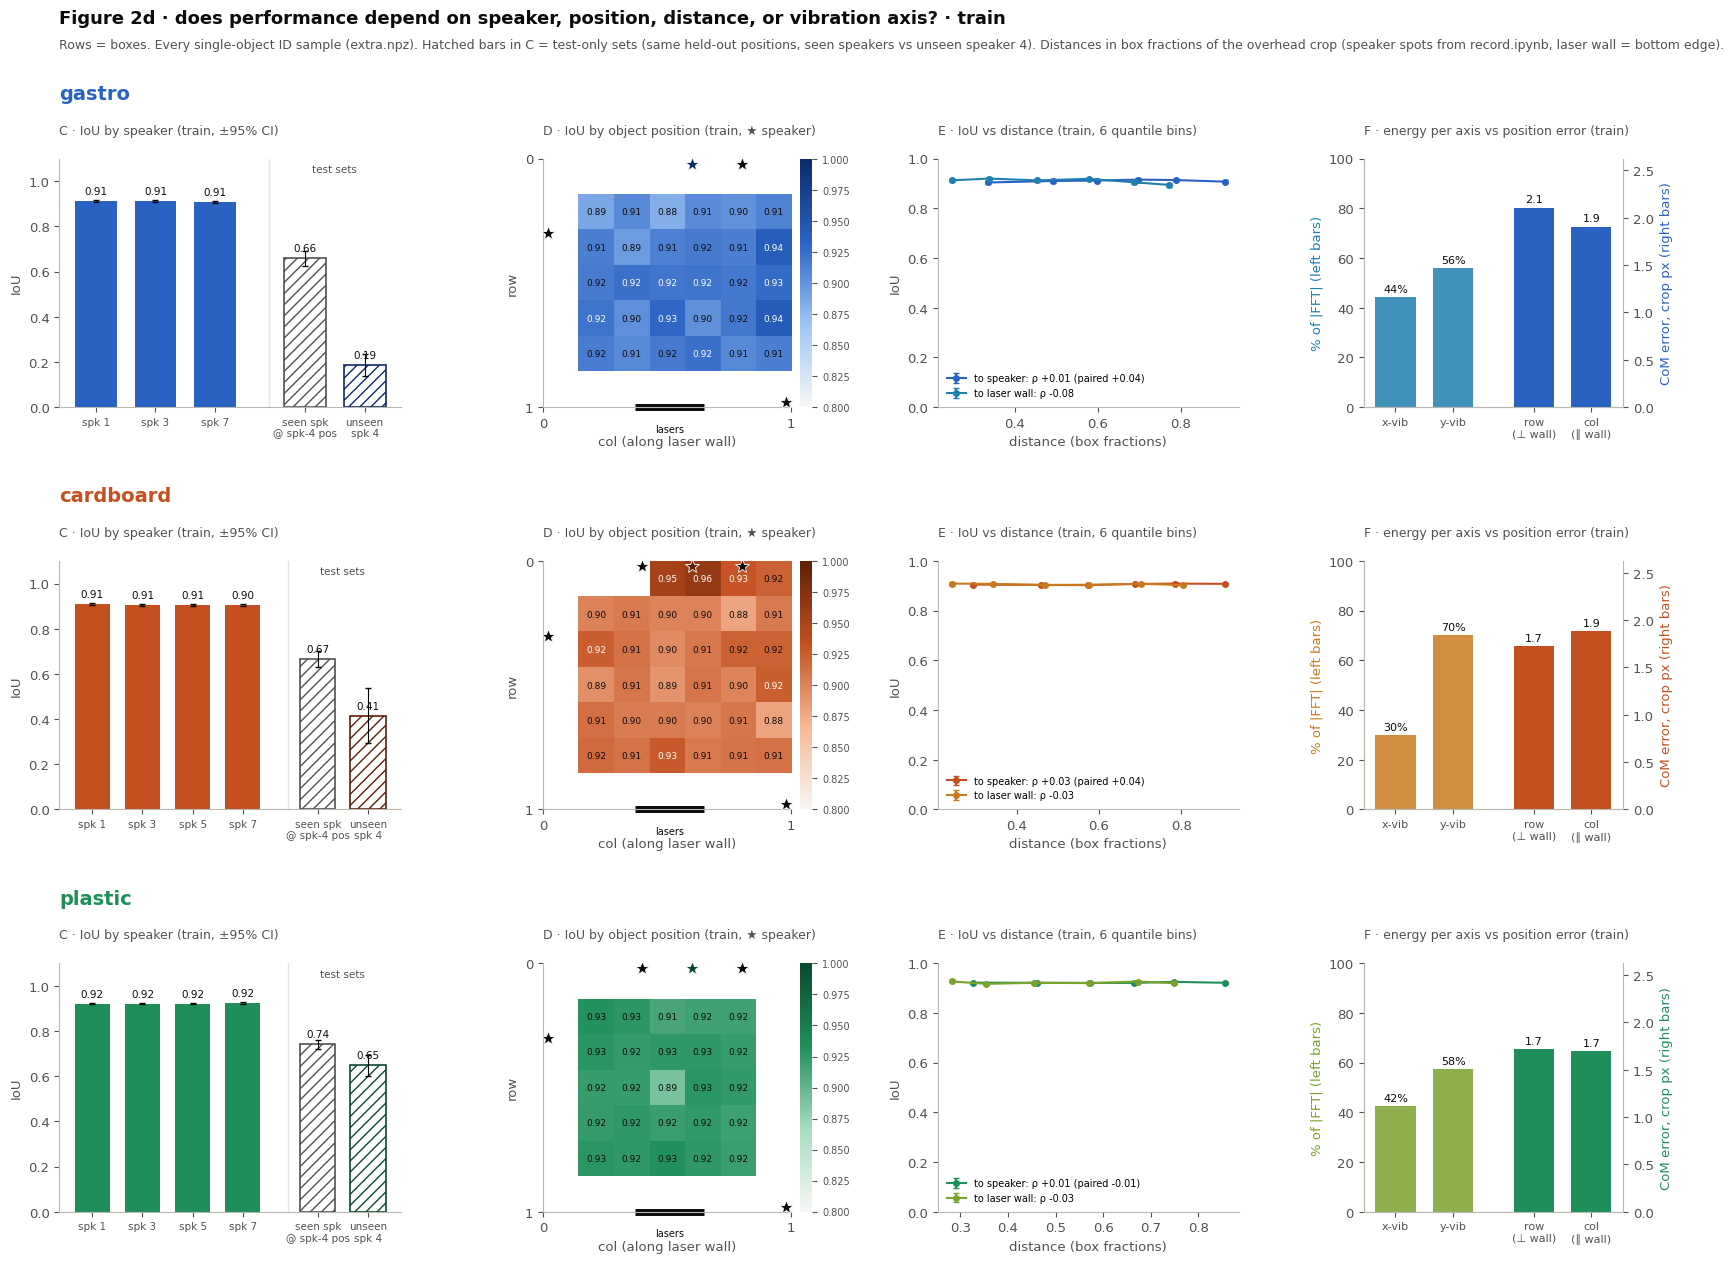

                IoU by speaker                    spk4 base→unseen  ρ d_spk (paired)  ρ d_las  x-vib %  CoM err row/col px
train gastro    1:0.911 3:0.911 7:0.910           nan→nan      +0.01 (+0.04)     -0.08    44.2     2.1 / 1.9
train cardboard 1:0.909 3:0.906 5:0.906 7:0.904   nan→nan      +0.03 (+0.04)     -0.03    29.8     1.7 / 1.9
train plastic   1:0.922 3:0.922 5:0.922 7:0.924   nan→nan      +0.01 (-0.01)     -0.03    42.4     1.7 / 1.7
train floor IoU range {'gastro': (0.88, 0.94), 'cardboard': (0.88, 0.96), 'plastic': (0.89, 0.93)}
test  gastro    1:0.770 3:0.746 7:0.770           0.658→0.187      -0.03 (+0.01)     +0.06    44.2     9.9 / 11.6
test  cardboard 1:0.747 3:0.692 5:0.699 7:0.736   0.666→0.414      +0.14 (+0.15)     -0.13    29.8     14.0 / 13.8
test  plastic   1:0.790 3:0.787 5:0.784 7:0.788   0.741→0.650      +0.03 (+0.01)     -0.02    42.4     8.9 / 9.1
test floor IoU range {'gastro': (0.02, 0.9), 'cardboard': (0.44, 0.88), 'plastic': (0.65, 0.88)}


In [4]:
def fig_geo(s=SPLIT):
    fig = plt.figure(figsize=(17, 13))
    gs = fig.add_gridspec(3, 4, hspace=.62, wspace=.42, width_ratios=[1.25, 1.05, 1.1, .95], left=.05, right=.97, top=.86, bottom=.05)
    FG = {b: floor_grid(s, b) for b in BX}; lo = np.floor(10 * np.nanmin([np.nanmin(v) for v in FG.values()])) / 10
    for r, b in enumerate(BX):
        cl, ci_, dk = FAM[b][0][3], FAM[b][1][2], FAM[b][1][3]; m = sel(s, b); g = G[s, b]
        # C · IoU per speaker (bars) + unseen speaker 4 (test sets only)
        a = fig.add_subplot(gs[r, 0]); ks = [k for k in (1, 3, 5, 7) if (m & (E["spk"] == k)).any()]
        v = [E["iou"][m & (E["spk"] == k)] for k in ks]; x = np.arange(len(ks))
        a.bar(x, [u.mean() for u in v], .7, yerr=[ci(u) for u in v], color=ci_, capsize=2, error_kw=dict(lw=.8))
        vb, vu = E["iou"][sel("test", b, "spk4-base")], E["iou"][sel("test", b, "spk4")]; xx = [len(ks) + .5, len(ks) + 1.5]
        a.bar(xx, [vb.mean(), vu.mean()], .7, yerr=[ci(vb), ci(vu)], color="white", edgecolor=[MUTE, dk], hatch="///", lw=1.2, capsize=2, error_kw=dict(lw=.8))
        for xi, u in zip(list(x) + xx, [u.mean() for u in v] + [vb.mean(), vu.mean()]): a.text(xi, u + .03, f"{u:.2f}", ha="center", fontsize=7.5, color=INK)
        a.axvline(len(ks) - .1, color=GRID, lw=1); a.text(np.mean(xx), 1.04, "test sets", ha="center", fontsize=7.5, color=MUTE)
        a.set_xticks(list(x) + xx, [f"spk {k}" for k in ks] + ["seen spk\n@ spk-4 pos", "unseen\nspk 4"], fontsize=7.5); a.set_ylim(0, 1.1); a.set_ylabel("IoU")
        a.text(0, 1.24, b, transform=a.transAxes, color=ci_, fontsize=14, fontweight="bold")
        a.text(0, 1.1, f"C · IoU by speaker ({s}, ±95% CI)", transform=a.transAxes, fontsize=9, color=MUTE)
        # D · IoU on the floor, numbers in the cells
        a = fig.add_subplot(gs[r, 1]); cm = LinearSegmentedColormap.from_list(f"f{b}", FAM[b][1]); nm_ = Normalize(lo, 1); F = FG[b]
        h = a.imshow(F, cmap=cm, norm=nm_, extent=(0, 1, 1, 0))
        for i in range(7):
            for j in range(7):
                if not np.isnan(F[i, j]): a.text((j + .5) / 7, (i + .5) / 7, f"{F[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if lum(cm(nm_(F[i, j]))) < .45 else INK)
        for k, (xs_, ys_) in SPK.items():
            if k in E["spk"][E["box"] == b]: a.plot(np.clip(xs_, .02, .98), np.clip(1 - ys_, .02, .98), "*", color=INK if k != 4 else dk, ms=10, mec="white", mew=.6, clip_on=False, zorder=5)
        a.plot(LASER, (1, 1), color=INK, lw=5, solid_capstyle="butt", clip_on=False); a.text(np.mean(LASER), 1.1, "lasers", ha="center", fontsize=7, color=INK)
        a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xlabel("col (along laser wall)"); a.set_ylabel("row")
        cb = fig.colorbar(h, ax=a, fraction=.046, pad=.03); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=7)
        a.text(0, 1.1, f"D · IoU by object position ({s}, ★ speaker)", transform=a.transAxes, fontsize=9, color=MUTE)
        # E · IoU vs distance to speaker / laser wall
        a = fig.add_subplot(gs[r, 2])
        for key, col, nm in (("d_spk", ci_, f"to speaker: ρ {g['r_spk']:+.2f} (paired {g['r_spk_res']:+.2f})"), ("d_las", cl, f"to laser wall: ρ {g['r_las']:+.2f}")):
            d_, u = E[key][m], E["iou"][m]; q = np.quantile(d_, np.linspace(0, 1, 7)); k_ = np.clip(np.searchsorted(q, d_, side="right") - 1, 0, 5)
            a.errorbar([np.median(d_[k_ == i]) for i in range(6)], [u[k_ == i].mean() for i in range(6)], [ci(u[k_ == i]) for i in range(6)], color=col, marker="o", ms=4, capsize=2, label=nm)
        a.set_ylim(0, 1); a.set_xlabel("distance (box fractions)"); a.set_ylabel("IoU"); a.legend(fontsize=7, loc="lower left")
        a.text(0, 1.1, f"E · IoU vs distance ({s}, 6 quantile bins)", transform=a.transAxes, fontsize=9, color=MUTE)
        # F · energy per vibration axis vs CoM error per floor axis
        a = fig.add_subplot(gs[r, 3])
        a.bar([0, 1], [g["xs"], 100 - g["xs"]], color=cl, alpha=.85, width=.7); a.set_ylim(0, 100); a.set_ylabel("% of |FFT| (left bars)", color=cl)
        for i, u in enumerate([g["xs"], 100 - g["xs"]]): a.text(i, u + 2, f"{u:.0f}%", ha="center", fontsize=8, color=INK)
        t = a.twinx(); t.bar([2.4, 3.4], g["err"], color=ci_, width=.7); t.set_ylabel("CoM error, crop px (right bars)", color=ci_); t.spines["right"].set_visible(True)
        for i, u in zip((2.4, 3.4), g["err"]): t.text(i, u * 1.03, f"{u:.1f}", ha="center", fontsize=8, color=INK)
        t.set_ylim(0, max(G[s, bb]["err"].max() for bb in BX) * 1.25)
        a.set_xticks([0, 1, 2.4, 3.4], ["x-vib", "y-vib", "row\n(⊥ wall)", "col\n(∥ wall)"], fontsize=8)
        a.text(0, 1.1, f"F · energy per axis vs position error ({s})", transform=a.transAxes, fontsize=9, color=MUTE)
    fig.suptitle(f"Figure 2d · does performance depend on speaker, position, distance, or vibration axis? · {s}", x=.05, y=.975, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.text(.05, .945, "Rows = boxes. Every single-object ID sample (extra.npz). Hatched bars in C = test-only sets (same held-out positions, seen speakers vs unseen speaker 4). "
             "Distances in box fractions of the overhead crop (speaker spots from record.ipynb, laser wall = bottom edge).", fontsize=9, color=MUTE)
    save(fig, f"geometry_{s}")
fig_geo()
print(f"{'':16s}{'IoU by speaker':34s}{'spk4 base→unseen':18s}{'ρ d_spk (paired)':18s}{'ρ d_las':9s}{'x-vib %':9s}{'CoM err row/col px'}")
for st in ("train", "test"):
    for b in BX:
        g = G[st, b]; print(f"{st:6s}{b:10s}{' '.join(f'{k}:{v:.3f}' for k, v in g['spk'].items()):34s}{g['s4b']:.3f}→{g['s4']:.3f}      {g['r_spk']:+.2f} ({g['r_spk_res']:+.2f})     {g['r_las']:+.2f}    {g['xs']:.1f}     {g['err'][0]:.1f} / {g['err'][1]:.1f}")
    print(st, "floor IoU range", {b: (round(float(np.nanmin(floor_grid(st, b))), 2), round(float(np.nanmax(floor_grid(st, b))), 2)) for b in BX})

### Claims decided by figure 2d
Verdicts: ✅ supported · 🟡 partly · ❌ refuted. Numbers are gastro / cardboard / plastic. Claims are numbered in the order they were posed.

### Claim 1 · "As speaker, box position, distance to speaker, distance to laser change, the performance remains the same" → 🟡 partly (✅ on train and for seen speakers; ❌ for an unseen speaker and at some unseen positions)
- **Seen speakers: ✅.** 2d-C bars. Train IoU: gastro .911 / .911 / .910, cardboard .904–.909, plastic .922–.924, so ≤ .005 spread. On test (`SPLIT = "test"`) the spread is ≤ .055: gastro .746–.770, cardboard .692–.747, plastic .784–.790.
- **Unseen speaker: ❌.** 2d-C hatched bars (test sets only, same held-out positions). Seen speakers → speaker 4: **.66 → .19** (gastro), **.67 → .41** (cardboard), **.74 → .65** (plastic). Speaker identity does not generalise; plastic degrades least.
- **Distance to speaker: ✅.** 2d-E, flat lines. Train Spearman ρ(IoU, distance) +.01 / +.03 / +.01, paired (position removed) +.04 / +.04 / −.01. Test −.03 / +.14 / +.03 (paired +.01 / +.15 / +.01); only cardboard moves, and farther is better.
- **Distance to laser wall: ✅.** 2d-E. Train ρ −.08 / −.03 / −.03; test +.06 / −.13 / −.02.
- **Box position: ✅ on train, ❌ on test.** 2d-D cell numbers. Train IoU per floor bin spans .88–.94 / .88–.96 / .89–.93. On test it spans **.02–.90 / .44–.88 / .65–.88**: unseen positions fail in pockets that neither distance explains (2d-E).

### Claim 2 · "It is easier to predict x/y position because there is more energy in the x/y direction (per box)" → ❌ refuted
- **Energy is lopsided.** 2d-F. The y-vibration axis carries more |FFT| in every box: x = 44 / 30 / 42%, y = 56 / 70 / 58% (test; train identical to 0.1%).
- **Error is not.** 2d-F right bars. Train CoM error rows vs cols: 2.1 vs 1.9, 1.7 vs 1.9, 1.7 vs 1.7 px; test 9.9 vs 11.6, 14.0 vs 13.8, 8.9 vs 9.1 px. Cardboard has the most lopsided energy (70% y) and the most balanced error (14.0 vs 13.8).
- **Within a box, no link.** Per-sample Spearman ρ(x-energy share, row error − col error) = −.02 / +.02 / .00 (test), −.05 / +.01 / .00 (train).
- Caveat: which vibration axis maps to which floor axis is not defined by the setup (x/y are the laser-spot motion on the wall camera). The claim fails under either mapping, because neither floor axis is consistently easier.